# SPHEREx × DESI real-space cross-correlation, v2

Follow-up to `2026-09-24-claude.ipynb` (2000 galaxies + 20000 randoms, 19 min). Changes:

- **Coarser bins**: `R = 40` in wavelength (about SPHEREx's band-3 resolving power; the R = 120 bins were just
  correlated), a wider rest-frame window (≈ 590–730 nm, so there is continuum on both sides of Hα + [NII] and
  [SII]), and 8 radial bins: `[0, 0.05]` then log-spaced to 0.8 cMpc (the old innermost 26 kpc bin got ~0.2
  measurements per object).
- **Full sample**: every ELG in the z-bin (`N_DATA = None`) and `RAND_PER_DATA = 5`, using every random file found
  in `../data/`.
- **Jackknife errors** over `N_JACKKNIFE` k-means sky regions, replacing the per-object bootstrap. Leave-one-out sums
  are total − region, so this is cheap.
- **Hα line excess**: J in the Hα bin minus the mean of line-free continuum bins, with jackknife errors.
- **Pair-count diagnostics**: the first run showed data objects getting ~2% more measurements than randoms. The stack
  now also records per-object pixel counts inside the disc and inside Gaia masks, and there are weighted/unweighted
  comparisons.
- **Checkpointing**: the main loop saves progress every few minutes and resumes if re-run with the same sample.
- **Quick look**: an optional section rebins the first run's saved stack onto coarse bins, so you can look before
  launching the long run.

In [15]:
%env TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable

import hashlib
import itertools
import threading
import time
import warnings
from collections import defaultdict
from glob import glob
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor, as_completed
from pathlib import Path

import duckdb
import healpy as hp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import pyvo
from astropy import constants as const
from astropy import units as u
from astropy.cosmology import Planck18
from astropy.io import fits
from astropy.table import Table, unique, vstack
from pyvo.dal.exceptions import DALServiceError
from scipy.cluster.vq import kmeans2
from scipy.spatial import cKDTree
from tqdm.auto import tqdm

from talltable.constants import HP_HIGH_LEVEL
from talltable.partition import find_partitions_disc, part_to_level_index
from talltable.paths import PART_DB_PATH, PIXEL_DB_PATH, WAVES_DB_PATH
from talltable.query import indices_to_hphigh_ranges

env: TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable


## configuration

In [2]:
Z_MIN, Z_MAX = 1.0, 1.01
N_DATA = None             # data sample size; None -> every galaxy in the z-bin
RAND_PER_DATA = 5         # N_R = RAND_PER_DATA * N_D (capped by what the random files hold)

DATA_PATH  = '../data/ELG_LOPnotqso_NGC_clustering.dat.fits'
RAND_PATHS = sorted(glob('../data/ELG_LOPnotqso_NGC_*_clustering.ran.fits'))   # every random file present
assert RAND_PATHS, "no random catalogs found"

WL_REST_HALPHA = 0.656    # µm
N_WL_BINS = 9
RESOLUTION = 40           # ~ SPHEREx band-3 resolving power

R_MAX_CMPC = 0.8          # comoving transverse radius of the stack [Mpc]
R_BIN_MIN = 0.05          # first radial bin is [0, R_BIN_MIN]; log-spaced above
N_R_BINS = 8

GAIA_G_MAX = 20.0         # mask Gaia stars brighter than this
GAIA_G_BRIGHT = 9.0       # stars brighter than this are fetched all-sky (their masks are large)
GAIA_CACHE_DIR = Path('../data/gaia_cache')

ALLOWED_FLAGS = 1 << 21   # allow bit 21 (SOURCE), reject every other flag
RANGE_LEVEL = 14          # HEALPix level of the hphigh ranges used to select row groups and rows

N_WORKERS = 16            # partitions processed concurrently (reads are latency-bound on ceph)

N_JACKKNIFE = 50          # sky regions for jackknife errors

OUT_PATH = Path('../data/stack_2026-09-24-v2.npz')
CHECKPOINT_PATH = OUT_PATH.with_suffix('.partial.npz')
CHECKPOINT_EVERY_S = 300

PREV_OUT_PATH = Path('../data/stack_2026-09-24.npz')   # first run, used by the quick look

RNG = np.random.default_rng(110)

## load catalogs

In [3]:
def load_catalog(paths, n=None):
    cols = defaultdict(list)
    for path in paths:
        with fits.open(path, memmap=True) as hdul:
            x = hdul[1].data
            m = (x['Z'] > Z_MIN) & (x['Z'] < Z_MAX)
            print(f"  {Path(path).name}: {len(x)} rows, {m.sum()} after z cuts")
            cols['ra'].append(np.array(x['RA'][m], dtype=np.float64))
            cols['dec'].append(np.array(x['DEC'][m], dtype=np.float64))
            cols['z'].append(np.array(x['Z'][m], dtype=np.float64))
            if 'WEIGHT' in x.columns.names:
                cols['w'].append(np.array(x['WEIGHT'][m], dtype=np.float64))
            else:
                print(f"  WARNING: no WEIGHT column in {path}; using unit weights")
                cols['w'].append(np.ones(m.sum()))
    cat = {k: np.concatenate(v) for k, v in cols.items()}

    if n is not None:
        if n > len(cat['z']):
            print(f"  WARNING: asked for {n} objects but only {len(cat['z'])} available; using all")
        else:
            idx = RNG.choice(len(cat['z']), size=n, replace=False)
            cat = {k: v[idx] for k, v in cat.items()}
            print(f"  ..subsampled to {n}")
    return cat

print("Loading data:")
data = load_catalog([DATA_PATH], N_DATA)

print("\nLoading randoms:")
rand = load_catalog(RAND_PATHS, RAND_PER_DATA * len(data['z']))

N_D, N_R = len(data['z']), len(rand['z'])
print(f"\nN_D = {N_D}, N_R = {N_R} (ratio {N_R / N_D:.1f})")
print(f"sum of weights: data {data['w'].sum():.1f}, randoms {rand['w'].sum():.1f}")

Loading data:
  ELG_LOPnotqso_NGC_clustering.dat.fits: 1821322 rows, 27803 after z cuts

Loading randoms:
  ELG_LOPnotqso_NGC_0_clustering.ran.fits: 9719822 rows, 147732 after z cuts
  ELG_LOPnotqso_NGC_1_clustering.ran.fits: 9715719 rows, 148011 after z cuts
  ..subsampled to 139015

N_D = 27803, N_R = 139015 (ratio 5.0)
sum of weights: data 26810.0, randoms 120753.1


In [4]:
# one combined object table: data first, then randoms
objs = {k: np.concatenate([data[k], rand[k]]) for k in data}
is_rand = np.r_[np.zeros(N_D, bool), np.ones(N_R, bool)]
n_obj = len(is_rand)

obj_D_M   = Planck18.comoving_transverse_distance(objs['z']).to(u.Mpc).value
obj_theta = R_MAX_CMPC / obj_D_M                                   # stack radius [rad]
obj_vec   = hp.ang2vec(objs['ra'], objs['dec'], lonlat=True)       # (n_obj, 3) unit vectors

print(f"stack radius: {np.degrees(obj_theta).min() * 60:.3f}' - {np.degrees(obj_theta).max() * 60:.3f}'")

stack radius: 0.804' - 0.810'


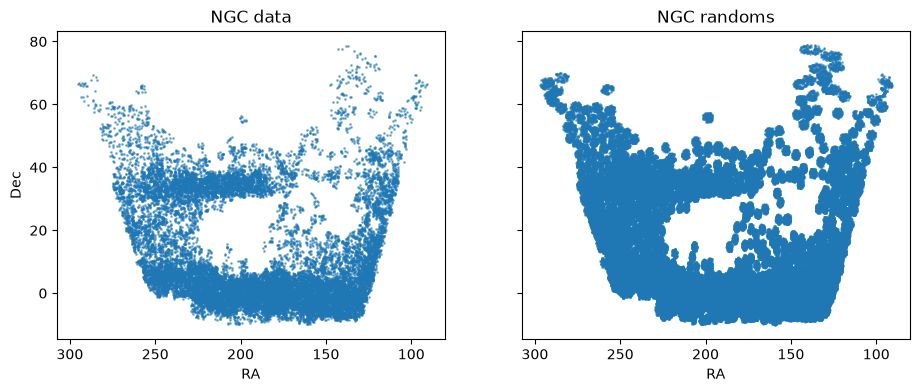

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, sel, title in [(axs[0], ~is_rand, 'data'), (axs[1], is_rand, 'randoms')]:
    ax.scatter(objs['ra'][sel], objs['dec'][sel], s=1, alpha=0.5)
    ax.set_title(f'NGC {title}')
    ax.set_xlabel('RA')
axs[0].set_ylabel('Dec')
axs[0].xaxis.set_inverted(True)
plt.show()

## choose bins

In [6]:
r_bins = np.r_[0, np.geomspace(R_BIN_MIN, R_MAX_CMPC, N_R_BINS)]

# rest-frame band around H-alpha, log-spaced at resolution R = lambda/dlambda
half_ln_width = (N_WL_BINS / RESOLUTION) / 2
WL_REST_MIN = WL_REST_HALPHA * np.exp(-half_ln_width)
WL_REST_MAX = WL_REST_HALPHA * np.exp(+half_ln_width)
wl_bins = np.geomspace(WL_REST_MIN, WL_REST_MAX, N_WL_BINS + 1)

# fixed observed-frame query band wide enough to cover every object's redshifted window
QUERY_WL_MIN = WL_REST_MIN * (1 + objs['z'].min())
QUERY_WL_MAX = WL_REST_MAX * (1 + objs['z'].max())

n_r, n_wl = len(r_bins) - 1, len(wl_bins) - 1
n_bins = n_r * n_wl

r_c  = 0.5 * (r_bins[:-1] + r_bins[1:])
wl_c = 0.5 * (wl_bins[:-1] + wl_bins[1:])

print("r edges [cMpc]:", np.round(r_bins, 3))
print("λ_rf edges [nm]:", np.round(wl_bins * 1e3, 1))

r edges [cMpc]: [0.    0.05  0.074 0.11  0.164 0.244 0.362 0.538 0.8  ]
λ_rf edges [nm]: [586.2 601.  616.3 631.9 647.9 664.3 681.1 698.3 716.  734.1]


## estimators and jackknife

With per-object sums $S_o$, counts $C_o$ and DESI weights $w_o$, and $W_X = \sum_{o \in X} w_o$:

- **difference of means**: $\hat J = \dfrac{\sum_D w S}{\sum_D w C} - \dfrac{\sum_R w S}{\sum_R w C}$
- **note's estimator**: $\hat J_{\rm note} = \dfrac{\sum_D w S / W_D - \sum_R w S / W_R}{\sum_R w C / W_R}$
- **pair-count ratio**: $(\sum_D w C / W_D) / (\sum_R w C / W_R)$. $\hat J_{\rm note} - \hat J = (\text{ratio} - 1) \langle I \rangle_D$.

Jackknife regions come from k-means on the randoms' unit vectors (randoms trace the footprint), and every object is
assigned to the nearest centroid. All weighted sums are accumulated per region, so each leave-one-out estimate is
just total − region.

**Hα line excess**: $\hat J$ in the bin containing Hα minus the mean over bins that contain none of the lines in
`LINES_NM` (or, if every bin has a line, all the other bins).

In [7]:
LINES_NM = {r'[OI]': 630.0, r'H$\alpha$': 656.3, r'[NII]': 658.4, r'[SII]': 671.6, r'[SII] ': 673.1}

def jackknife_regions(ra, dec, is_rand, n_regions, seed=0):
    vec = hp.ang2vec(ra, dec, lonlat=True)
    centroids, _ = kmeans2(vec[is_rand], n_regions, minit='++', rng=seed)
    return cKDTree(centroids).query(vec)[1]

def region_sums(S3, C3, w, region, sel, n_regions):
    # per-region weighted sums over the objects in `sel`: (n_regions, n_r, n_wl) for S and C, (n_regions,) for w
    Sg = np.zeros((n_regions,) + S3.shape[1:])
    Cg = np.zeros((n_regions,) + C3.shape[1:])
    Wg = np.zeros(n_regions)
    for g in range(n_regions):
        m = np.flatnonzero(sel & (region == g))
        Sg[g] = np.tensordot(w[m], S3[m], 1)
        Cg[g] = np.tensordot(w[m], C3[m], 1)
        Wg[g] = w[m].sum()
    return Sg, Cg, Wg

def estimators_from_sums(SD, CD, WD, SR, CR, WR):
    with np.errstate(divide='ignore', invalid='ignore'):
        J_diff = SD / CD - SR / CR
        J_note = (SD / WD - SR / WR) / (CR / WR)
        pc_ratio = (CD / WD) / (CR / WR)
    return np.array([J_diff, J_note, pc_ratio])

def measure(S3, C3, w, is_rand, region, n_regions):
    # returns (full, jk): full is (3, n_r, n_wl) = [J_diff, J_note, pc_ratio]; jk is (n_regions, 3, n_r, n_wl)
    D = region_sums(S3, C3, w, region, ~is_rand, n_regions)
    R = region_sums(S3, C3, w, region, is_rand, n_regions)
    tot = [x.sum(0) for x in D + R]
    full = estimators_from_sums(*tot)
    jk = np.array([
        estimators_from_sums(*[t - x[g] for t, x in zip(tot, D + R)])
        for g in range(n_regions)
    ])
    return full, jk

def jk_err(jk):
    n = len(jk)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        return np.sqrt((n - 1) / n * np.nansum((jk - np.nanmean(jk, axis=0)) ** 2, axis=0))

def line_and_continuum(wl_bins):
    lo, hi = wl_bins[:-1] * 1e3, wl_bins[1:] * 1e3
    has_line = np.array([any(l <= x < h for x in LINES_NM.values()) for l, h in zip(lo, hi)])
    j_line = np.flatnonzero((lo <= WL_REST_HALPHA * 1e3) & (WL_REST_HALPHA * 1e3 < hi))[0]
    cont = np.flatnonzero(~has_line)
    if len(cont) == 0:
        cont = np.setdiff1d(np.arange(len(lo)), [j_line])
    return j_line, cont

def line_excess(J, j_line, cont):
    # works on (..., n_r, n_wl)
    return J[..., j_line] - J[..., cont].mean(axis=-1)

def plot_J(full, jk, r_bins, wl_bins, title=''):
    J, J_err = full[0], jk_err(jk[:, 0])
    rc = 0.5 * (r_bins[:-1] + r_bins[1:])
    wc = 0.5 * (wl_bins[:-1] + wl_bins[1:])
    j_line, cont = line_and_continuum(wl_bins)

    fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))

    ax = axs[0]
    cmap, norm = plt.get_cmap('viridis'), mpl.colors.Normalize(rc.min(), rc.max())
    for i in range(len(rc)):
        ax.errorbar(wc * 1e3, J[i], J_err[i], marker='o', capsize=2, color=cmap(norm(rc[i])))
    for name, x in LINES_NM.items():
        ax.axvline(x, color='0.7', lw=0.8, ls='--', zorder=0)
        ax.text(x, 1.0, name.strip(), transform=ax.get_xaxis_transform(), rotation=90, va='top', ha='right', fontsize=8)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel(r'$\lambda_{\rm rf}$ [nm]')
    ax.set_ylabel(r'$\hat J$')
    fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$r_\perp$ [cMpc]')

    ax = axs[1]
    ax.errorbar(rc, J[:, j_line], J_err[:, j_line], marker='o', capsize=2, label=rf'H$\alpha$ bin ({wc[j_line] * 1e3:.0f} nm)')
    cont_J = J[:, cont].mean(1)
    cont_err = jk_err(jk[:, 0][:, :, cont].mean(-1))
    ax.errorbar(rc, cont_J, cont_err, marker='s', capsize=2, label=f'continuum ({len(cont)} bins)')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xscale('log')
    ax.set_xlabel(r'$r_\perp$ [cMpc]')
    ax.set_ylabel(r'$\hat J$')
    ax.legend()

    ax = axs[2]
    ex = line_excess(J, j_line, cont)
    ex_err = jk_err(line_excess(jk[:, 0], j_line, cont))
    ax.errorbar(rc, ex, ex_err, marker='o', capsize=2, color='C3')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xscale('log')
    ax.set_xlabel(r'$r_\perp$ [cMpc]')
    ax.set_ylabel(r'H$\alpha$ line excess')

    fig.suptitle(title)
    plt.show()

    print(f"H-alpha line excess (bin {wc[j_line] * 1e3:.0f} nm minus continuum bins {np.round(wc[cont] * 1e3).astype(int)} nm):")
    for i in range(len(rc)):
        print(f"  r = {r_bins[i]:.3f} - {r_bins[i + 1]:.3f} cMpc: {ex[i]: .3e} ± {ex_err[i]:.3e}  (S/N {ex[i] / ex_err[i]: .1f})")

## quick look: first run, rebinned (optional)

Rebins the first run's saved per-object sums (`PREV_OUT_PATH`, R = 120 and 26 kpc bins) onto coarser bins by summing
fine bins: radial edges are the old edges nearest to this notebook's `r_bins`, and wavelength bins are merged in
threes (R ≈ 40), centered on Hα. Only needs the cells above (no Gaia or talltable reads).

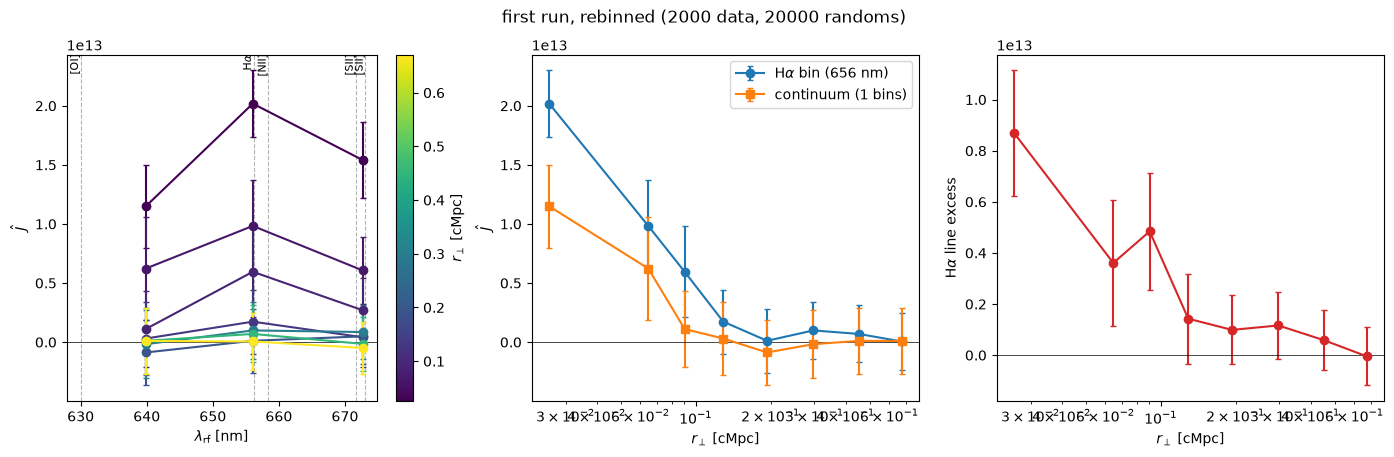

H-alpha line excess (bin 656 nm minus continuum bins [640] nm):
  r = 0.000 - 0.052 cMpc:  8.688e+12 ± 2.459e+12  (S/N  3.5)
  r = 0.052 - 0.077 cMpc:  3.608e+12 ± 2.466e+12  (S/N  1.5)
  r = 0.077 - 0.103 cMpc:  4.844e+12 ± 2.281e+12  (S/N  2.1)
  r = 0.103 - 0.155 cMpc:  1.427e+12 ± 1.754e+12  (S/N  0.8)
  r = 0.155 - 0.232 cMpc:  9.888e+11 ± 1.346e+12  (S/N  0.7)
  r = 0.232 - 0.361 cMpc:  1.164e+12 ± 1.327e+12  (S/N  0.9)
  r = 0.361 - 0.542 cMpc:  5.894e+11 ± 1.185e+12  (S/N  0.5)
  r = 0.542 - 0.800 cMpc: -4.131e+10 ± 1.137e+12  (S/N -0.0)


In [8]:
def merge_bins(A, axis, edge_idx):
    # sum fine bins [edge_idx[k], edge_idx[k+1]) along `axis`
    A = np.take(A, np.arange(edge_idx[0], edge_idx[-1]), axis=axis)
    return np.add.reduceat(A, edge_idx[:-1] - edge_idx[0], axis=axis)

if PREV_OUT_PATH.exists():
    f = np.load(PREV_OUT_PATH)
    rb0, wb0 = f['r_bins'], f['wl_bins']
    nr0, nw0 = len(rb0) - 1, len(wb0) - 1
    S_prev = f['S'].reshape(-1, nr0, nw0)
    C_prev = f['C'].reshape(-1, nr0, nw0)

    r_idx = np.unique([np.argmin(np.abs(rb0 - e)) for e in r_bins])
    wl_idx = np.arange((nw0 % 3) // 2, nw0 + 1, 3)
    S_q = merge_bins(merge_bins(S_prev, 1, r_idx), 2, wl_idx)
    C_q = merge_bins(merge_bins(C_prev, 1, r_idx), 2, wl_idx)

    is_rand_q = f['is_rand']
    region_q = jackknife_regions(f['obj_ra'], f['obj_dec'], is_rand_q, N_JACKKNIFE)
    full_q, jk_q = measure(S_q, C_q, f['obj_w'], is_rand_q, region_q, N_JACKKNIFE)
    plot_J(full_q, jk_q, rb0[r_idx], wb0[wl_idx],
           title=f'first run, rebinned ({(~is_rand_q).sum()} data, {is_rand_q.sum()} randoms)')
else:
    print(f"{PREV_OUT_PATH} not found; skipping quick look")

## Gaia star mask

Two tiers, both fetched once from IRSA TAP and cached under `GAIA_CACHE_DIR`:

- **bright** (`G < GAIA_G_BRIGHT`): all-sky, ~180k stars, ~35 s (cached from the first run). These have masks up to degrees, so
  they must be found far from the objects.
- **faint** (`GAIA_G_BRIGHT <= G < GAIA_G_MAX`): a single upload-join cone search around every object
  (chunked), with radius = largest stack radius + mask radius at `GAIA_G_BRIGHT`. About 10 s per 2000
  objects.

The faint-tier cache file is keyed by a hash of the object positions and query radius, so changing the
sample triggers a re-fetch. To force one, delete the cache files.

With ~170k objects the faint-tier fetch is ~35 upload queries; expect roughly 10 minutes the first time.

In [9]:
IRSA_TAP = pyvo.dal.TAPService('https://irsa.ipac.caltech.edu/TAP')

def crude_mask_radius(m):
    # arcsec
    return 8.0 + 4e3 * 10 ** (-0.25 * m)

def run_tap(query, uploads=None, max_retries=5):
    for attempt in range(max_retries):
        try:
            return IRSA_TAP.run_async(query, uploads=uploads, maxrec=50_000_000).to_table()
        except DALServiceError:
            if attempt == max_retries - 1:
                raise
            time.sleep(2 ** attempt + np.random.uniform(0, 1))

def fetch_gaia_bright():
    cache = GAIA_CACHE_DIR / f'gaia_dr3_G_lt_{GAIA_G_BRIGHT:g}.fits'
    if cache.exists():
        return Table.read(cache)
    t = run_tap(f'''
SELECT source_id, ra, dec, phot_g_mean_mag
FROM gaia_dr3_source
WHERE phot_g_mean_mag < {GAIA_G_BRIGHT}
''')
    cache.parent.mkdir(parents=True, exist_ok=True)
    t.write(cache)
    return t

def fetch_gaia_near(ra, dec, radius_deg, chunk=5000):
    key = hashlib.sha1(
        np.round(ra, 6).tobytes() + np.round(dec, 6).tobytes()
        + f'{radius_deg:.6f},{GAIA_G_BRIGHT},{GAIA_G_MAX}'.encode()
    ).hexdigest()[:12]
    cache = GAIA_CACHE_DIR / f'gaia_dr3_near_{key}.fits'
    if cache.exists():
        return Table.read(cache)

    query = f'''
SELECT g.source_id, g.ra, g.dec, g.phot_g_mean_mag
FROM gaia_dr3_source AS g, TAP_UPLOAD.objs AS o
WHERE 1 = CONTAINS(POINT('ICRS', g.ra, g.dec), CIRCLE('ICRS', o.ra, o.dec, {radius_deg}))
AND g.phot_g_mean_mag >= {GAIA_G_BRIGHT}
AND g.phot_g_mean_mag < {GAIA_G_MAX}
'''
    tables = []
    for i in tqdm(range(0, len(ra), chunk), desc='gaia (faint)'):
        upload = Table({'ra': ra[i:i + chunk], 'dec': dec[i:i + chunk]})
        tables.append(run_tap(query, uploads={'objs': upload}))
    t = unique(vstack(tables), keys='source_id')   # neighboring cones overlap

    cache.parent.mkdir(parents=True, exist_ok=True)
    t.write(cache)
    return t

In [10]:
def make_star_set(t):
    g = np.ma.filled(np.asarray(t['phot_g_mean_mag'], dtype=np.float64), np.nan)
    ok = np.isfinite(g)
    ra, dec = np.asarray(t['ra'], np.float64)[ok], np.asarray(t['dec'], np.float64)[ok]
    vec = hp.ang2vec(ra, dec, lonlat=True).reshape(-1, 3)
    r_mask = np.radians(crude_mask_radius(g[ok]) / 3600)
    return {
        'vec': vec,
        'r_mask': r_mask,
        'r_max': r_mask.max() if len(r_mask) else 0.0,
        'tree': cKDTree(vec),
    }

t0 = time.time()
gaia_bright = fetch_gaia_bright()
faint_radius_deg = np.degrees(obj_theta.max()) + crude_mask_radius(GAIA_G_BRIGHT) / 3600
gaia_faint = fetch_gaia_near(objs['ra'], objs['dec'], faint_radius_deg)
print(f"Gaia: {len(gaia_bright)} bright + {len(gaia_faint)} faint stars ({time.time() - t0:.0f} s)")

star_sets = [make_star_set(gaia_bright), make_star_set(gaia_faint)]

Gaia: 177426 bright + 955518 faint stars (0 s)


## assign objects to partitions

Each talltable partition is a nested-HEALPix cell (levels 6-10, adaptive) and every sky pixel belongs to
exactly one partition. Build the inverse map partition → [objects whose disc touches it].

In [11]:
with open(PART_DB_PATH) as f:
    ALL_PARTS = {int(line) for line in f if line.strip()}

part_objs = defaultdict(list)
for k in tqdm(range(n_obj), desc='partitions'):
    for p in find_partitions_disc(objs['ra'][k], objs['dec'][k], np.degrees(obj_theta[k]), all_parts=ALL_PARTS):
        part_objs[int(p)].append(k)
part_objs = {p: np.array(ks) for p, ks in part_objs.items()}

n_per_part = np.array([len(ks) for ks in part_objs.values()])
n_pairs = n_per_part.sum()
print(f"{len(part_objs)} partitions for {n_obj} objects")
print(f"objects per partition: median {np.median(n_per_part):.0f}, max {n_per_part.max()}")
print(f"(object, partition) pairs: {n_pairs} ({n_pairs / n_obj:.2f} partitions per object)")

partitions:   0%|          | 0/166818 [00:00<?, ?it/s]

8495 partitions for 166818 objects
objects per partition: median 20, max 73
(object, partition) pairs: 182857 (1.10 partitions per object)


## query & stack

For each partition, `process_partition`:

1. builds `hphigh` ranges (level `RANGE_LEVEL`) covering the union of its objects' discs, clipped to the partition;
2. reads the parquet footer, keeps only the **row groups** whose `hphigh` min/max overlaps a range, and reads just
   those (with `pre_buffer=True`, so each row group's column chunks come in as a few large coalesced reads rather
   than scattered small ones);
3. filters rows in numpy: inside a range, allowed flags, `waveid` in the observed-frame window;
4. marks pixels inside any Gaia mask (KD-tree over the partition's unique sky pixels);
5. assigns pixels to each object with the same KD-tree, bins in `(r, λ_rest)` and returns per-object
   sums `S = Σ I_rest` and counts `C = Σ 1`, plus per-object counts of unique sky pixels inside the disc and
   inside Gaia masks (for the coverage diagnostics).

This replaced a single DuckDB query per partition: DuckDB only used the overall `hphigh` min/max for row-group
pruning, not the OR of ranges, so for objects spread across a partition it scanned most of the file (tens of millions
of rows) and evaluated hundreds of `BETWEEN`s per row.

The main thread adds the per-object results into `S_all`, `C_all` with shape `(n_obj, n_r * n_wl)`.

In [12]:
# waves in the observed-frame window, loaded once, sorted by waveid for lookups
_waves = duckdb.sql(f'''
SELECT waveid, wavelength
FROM read_parquet('{WAVES_DB_PATH}')
WHERE wavelength BETWEEN {QUERY_WL_MIN} AND {QUERY_WL_MAX}
ORDER BY waveid
''').fetchnumpy()
WAVE_IDS = np.asarray(_waves['waveid'])
WAVE_WL  = np.asarray(_waves['wavelength'])
print(f"{len(WAVE_IDS)} waveids in {QUERY_WL_MIN:.4f} - {QUERY_WL_MAX:.4f} µm")

C_UM_HZ = const.c.to(u.um / u.s).value   # nu [Hz] = C_UM_HZ / lambda [µm]
PIXEL_COLUMNS = ['hphigh', 'waveid', 'flux', 'zodi', 'flags']

def chord(angle):
    # KD-trees work in 3D Euclidean distance between unit vectors
    return 2 * np.sin(0.5 * np.asarray(angle))

def flatten_idx(lists):
    return np.fromiter(itertools.chain.from_iterable(lists), dtype=np.intp)

def partition_path(part):
    return PIXEL_DB_PATH / f'part={part}' / 'compacted.parquet'

def partition_span(part):
    level, index = part_to_level_index(int(part))
    shift = 2 * (HP_HIGH_LEVEL - level)
    return index << shift, ((index + 1) << shift) - 1

def disc_ranges(vecs, radii, span, level=RANGE_LEVEL):
    # sorted, merged, inclusive hphigh ranges covering the union of discs, clipped to the partition span
    lo_p, hi_p = span
    ipix = np.concatenate([
        hp.query_disc(2**level, v, r, nest=True, inclusive=True)
        for v, r in zip(vecs, radii)
    ])
    ranges = np.array(indices_to_hphigh_ranges(ipix, level), dtype=np.int64).reshape(-1, 2)
    ranges[:, 0] = np.maximum(ranges[:, 0], lo_p)
    ranges[:, 1] = np.minimum(ranges[:, 1], hi_p)
    return ranges[ranges[:, 0] <= ranges[:, 1]]

def last_range_starting_at_or_before(x, ranges):
    # ranges are sorted and non-overlapping, so this range also has the largest `hi` among those starting <= x
    return np.searchsorted(ranges[:, 0], x, side='right') - 1

def select_row_groups(pf, ranges):
    md = pf.metadata
    j = pf.schema_arrow.get_field_index('hphigh')
    lo = np.full(md.num_row_groups, np.iinfo(np.int64).min)
    hi = np.full(md.num_row_groups, np.iinfo(np.int64).max)
    for g in range(md.num_row_groups):
        st = md.row_group(g).column(j).statistics
        if st is not None and st.has_min_max:
            lo[g], hi[g] = st.min, st.max
    # row group [lo, hi] overlaps a range iff the last range starting <= hi ends >= lo
    i = last_range_starting_at_or_before(hi, ranges)
    return np.flatnonzero((i >= 0) & (ranges[np.maximum(i, 0), 1] >= lo))

def read_partition(part, ranges):
    # returns (hphigh, wavelength, flux, zodi) for good pixels inside `ranges`, or None
    pf = pq.ParquetFile(partition_path(part), pre_buffer=True)
    rgs = select_row_groups(pf, ranges)
    if len(rgs) == 0:
        return None
    t = pf.read_row_groups(rgs, columns=PIXEL_COLUMNS)

    h = t.column('hphigh').to_numpy()
    i = last_range_starting_at_or_before(h, ranges)
    keep = (i >= 0) & (h <= ranges[np.maximum(i, 0), 1])
    keep &= (t.column('flags').to_numpy().astype(np.int64) & ~ALLOWED_FLAGS) == 0
    idx = np.flatnonzero(keep)

    waveid = t.column('waveid').to_numpy()[idx]
    pos = np.minimum(np.searchsorted(WAVE_IDS, waveid), len(WAVE_IDS) - 1)
    in_window = WAVE_IDS[pos] == waveid
    idx, pos = idx[in_window], pos[in_window]
    return (
        h[idx],
        WAVE_WL[pos],
        t.column('flux').to_numpy()[idx],
        t.column('zodi').to_numpy()[idx],
    )

def star_mask(pix_tree, n_pix, ks):
    masked = np.zeros(n_pix, dtype=bool)
    for st in star_sets:
        if len(st['r_mask']) == 0:
            continue
        # stars that could reach any of these objects' discs
        cand = np.unique(flatten_idx(
            st['tree'].query_ball_point(obj_vec[ks], chord(obj_theta[ks] + st['r_max']))
        ))
        if cand.size == 0:
            continue
        hits = flatten_idx(pix_tree.query_ball_point(st['vec'][cand], chord(st['r_mask'][cand])))
        masked[hits] = True
    return masked

def process_partition(part, ks):
    # returns ks, S, C (per-object binned sums/counts), n_disc, n_masked (unique sky pixels in disc / in Gaia masks)
    S = np.zeros((len(ks), n_bins))
    C = np.zeros((len(ks), n_bins), dtype=np.int64)
    n_disc = np.zeros(len(ks), dtype=np.int64)
    n_masked = np.zeros(len(ks), dtype=np.int64)

    ranges = disc_ranges(obj_vec[ks], obj_theta[ks], partition_span(part))
    if len(ranges) == 0:
        return ks, S, C, n_disc, n_masked
    rows = read_partition(part, ranges)
    if rows is None or len(rows[0]) == 0:
        return ks, S, C, n_disc, n_masked
    hphigh, wl_obs, flux, zodi = rows
    I_obs = (C_UM_HZ / wl_obs) * (flux - zodi)   # nu I_nu

    # unique sky pixels; rows grouped by pixel (CSR layout: rows of pixel i are order[starts[i]:starts[i]+counts[i]])
    upix, inv = np.unique(hphigh, return_inverse=True)
    pix_vec = np.stack(hp.pix2vec(2**HP_HIGH_LEVEL, upix, nest=True), axis=1)
    pix_tree = cKDTree(pix_vec)
    order  = np.argsort(inv, kind='stable')
    counts = np.bincount(inv, minlength=len(upix))
    starts = np.cumsum(counts) - counts

    masked = star_mask(pix_tree, len(upix), ks)

    in_disc = pix_tree.query_ball_point(obj_vec[ks], chord(obj_theta[ks]))
    for j, k in enumerate(ks):
        sel = np.asarray(in_disc[j], dtype=np.intp)
        n_disc[j] = sel.size
        sel = sel[~masked[sel]]
        n_masked[j] = n_disc[j] - sel.size
        if sel.size == 0:
            continue

        sep = 2 * np.arcsin(0.5 * np.linalg.norm(pix_vec[sel] - obj_vec[k], axis=1))
        i_r_pix = np.digitize(sep * obj_D_M[k], r_bins) - 1

        lens = counts[sel]
        rows = order[np.repeat(starts[sel] - (np.cumsum(lens) - lens), lens) + np.arange(lens.sum())]
        i_r  = np.repeat(i_r_pix, lens)
        i_wl = np.digitize(wl_obs[rows] / (1 + objs['z'][k]), wl_bins) - 1

        ok = (i_r >= 0) & (i_r < n_r) & (i_wl >= 0) & (i_wl < n_wl)
        flat = i_r[ok] * n_wl + i_wl[ok]
        I_rest = (1 + objs['z'][k]) ** 4 * I_obs[rows[ok]]
        S[j] = np.bincount(flat, weights=I_rest, minlength=n_bins)
        C[j] = np.bincount(flat, minlength=n_bins)

    return ks, S, C, n_disc, n_masked

2293671 waveids in 1.1724 - 1.4756 µm


Optional: time a random sample of partitions (cold reads) before launching the full loop, and extrapolate.

In [13]:
# biggest partitions first, for load balance
parts = sorted(part_objs, key=lambda p: -len(part_objs[p]))

def profile_partition(part):
    ks = part_objs[part]
    t0 = time.perf_counter()
    ranges = disc_ranges(obj_vec[ks], obj_theta[ks], partition_span(part))
    pf = pq.ParquetFile(partition_path(part), pre_buffer=True)
    rgs = select_row_groups(pf, ranges) if len(ranges) else np.array([], int)
    t_meta = time.perf_counter() - t0

    t0 = time.perf_counter()
    if len(rgs):
        pf.read_row_groups(rgs, columns=PIXEL_COLUMNS)
    t_read = time.perf_counter() - t0

    t0 = time.perf_counter()
    process_partition(part, ks)   # whole thing again, now with a warm cache
    t_warm = time.perf_counter() - t0

    md = pf.metadata
    size_gb = partition_path(part).stat().st_size / 1e9
    print(f"part {part}: {len(ks):2d} objs, {len(ranges):3d} ranges | "
          f"{len(rgs):3d} / {md.num_row_groups} row groups ({md.num_rows / md.num_row_groups / 1e6:.2f}M rows each; "
          f"file {size_gb:.2f} GB) | meta {t_meta:.2f}s, read (cold) {t_read:.2f}s, all (warm) {t_warm:.2f}s")
    return t_meta + t_read + t_warm

sample = np.random.default_rng(0).choice(len(parts), size=min(8, len(parts)), replace=False)
t_cold = np.mean([profile_partition(parts[k]) for k in sample])
print(f"\n~{t_cold:.2f} s per partition -> ~{t_cold * len(parts) / N_WORKERS / 60:.0f} min "
      f"for {len(parts)} partitions with {N_WORKERS} workers (if reads scale that far)")

part 1057588:  5 objs,  69 ranges |   9 / 97 row groups (1.04M rows each; file 1.76 GB) | meta 0.03s, read (cold) 3.15s, all (warm) 0.50s
part 1075617: 43 objs, 578 ranges |  43 / 72 row groups (1.05M rows each; file 1.30 GB) | meta 0.03s, read (cold) 9.40s, all (warm) 2.65s
part 1074046: 51 objs, 655 ranges |  63 / 94 row groups (1.05M rows each; file 1.69 GB) | meta 0.03s, read (cold) 12.86s, all (warm) 3.96s
part 1076185: 19 objs, 255 ranges |  25 / 77 row groups (1.04M rows each; file 1.37 GB) | meta 0.02s, read (cold) 7.39s, all (warm) 1.39s
part 1056788: 29 objs, 350 ranges |  40 / 71 row groups (1.04M rows each; file 1.28 GB) | meta 0.08s, read (cold) 6.40s, all (warm) 2.35s
part 1056777: 31 objs, 392 ranges |  33 / 70 row groups (1.04M rows each; file 1.25 GB) | meta 0.02s, read (cold) 6.22s, all (warm) 1.94s
part 1080111: 47 objs, 560 ranges |  54 / 73 row groups (1.04M rows each; file 1.31 GB) | meta 0.05s, read (cold) 8.23s, all (warm) 3.08s
part 1052928: 14 objs, 166 ranges

Main loop. Progress is checkpointed to `CHECKPOINT_PATH` every `CHECKPOINT_EVERY_S` seconds and on interrupt; re-running
this cell with the same sample and bins resumes from it. The checkpoint is deleted once the final `OUT_PATH` is written.

In [16]:
S_all = np.zeros((n_obj, n_bins))
C_all = np.zeros((n_obj, n_bins), dtype=np.int64)
npix_disc = np.zeros(n_obj, dtype=np.int64)
npix_masked = np.zeros(n_obj, dtype=np.int64)
done_parts = set()

sample_key = hashlib.sha1(
    objs['ra'].tobytes() + objs['dec'].tobytes() + objs['z'].tobytes() + r_bins.tobytes() + wl_bins.tobytes()
).hexdigest()

if CHECKPOINT_PATH.exists():
    ck = np.load(CHECKPOINT_PATH)
    if str(ck['key']) == sample_key:
        S_all, C_all = ck['S'], ck['C']
        npix_disc, npix_masked = ck['npix_disc'], ck['npix_masked']
        done_parts = set(ck['done_parts'].tolist())
        print(f"resuming from checkpoint: {len(done_parts)} partitions already done")
    else:
        print("checkpoint is for a different sample or binning; starting over")

def save_checkpoint():
    tmp = CHECKPOINT_PATH.with_name(CHECKPOINT_PATH.stem + '.tmp.npz')
    np.savez(tmp, key=sample_key, S=S_all, C=C_all, npix_disc=npix_disc, npix_masked=npix_masked,
             done_parts=np.array(sorted(done_parts), dtype=np.int64))
    tmp.replace(CHECKPOINT_PATH)

# biggest partitions first, for load balance
parts = sorted(part_objs, key=lambda p: -len(part_objs[p]))
todo = [p for p in parts if p not in done_parts]

CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
t0 = last_ckpt = time.time()
# with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
    futures = {ex.submit(process_partition, p, part_objs[p]): p for p in todo}
    try:
        for fut in tqdm(as_completed(futures), total=len(futures), desc='partitions'):
            ks, S, C, nd, nm = fut.result()
            S_all[ks] += S
            C_all[ks] += C
            npix_disc[ks] += nd
            npix_masked[ks] += nm
            done_parts.add(futures[fut])
            if time.time() - last_ckpt > CHECKPOINT_EVERY_S:
                save_checkpoint()
                last_ckpt = time.time()
    except BaseException:
        ex.shutdown(wait=False, cancel_futures=True)
        save_checkpoint()
        print(f"interrupted; checkpoint saved with {len(done_parts)} / {len(parts)} partitions")
        raise
print(f"done in {time.time() - t0:.0f} s; {(C_all.sum(1) == 0).sum()} objects with no pixels")

np.savez_compressed(
    OUT_PATH, S=S_all, C=C_all, npix_disc=npix_disc, npix_masked=npix_masked,
    is_rand=is_rand, r_bins=r_bins, wl_bins=wl_bins,
    **{f'obj_{k}': v for k, v in objs.items()},
)
CHECKPOINT_PATH.unlink(missing_ok=True)

resuming from checkpoint: 3774 partitions already done


partitions:   0%|          | 0/4721 [00:00<?, ?it/s]

done in 1521 s; 28 objects with no pixels


In [17]:
# to reload a finished run instead of recomputing (after running the config, estimator and bins cells):
# f = np.load(OUT_PATH)
# S_all, C_all, is_rand, r_bins, wl_bins = f['S'], f['C'], f['is_rand'], f['r_bins'], f['wl_bins']
# npix_disc, npix_masked = f['npix_disc'], f['npix_masked']
# objs = {k[4:]: f[k] for k in f.files if k.startswith('obj_')}
# n_obj, n_r, n_wl = len(is_rand), len(r_bins) - 1, len(wl_bins) - 1
# r_c, wl_c = 0.5 * (r_bins[:-1] + r_bins[1:]), 0.5 * (wl_bins[:-1] + wl_bins[1:])

## results

jackknife: 50 regions, 62 - 1764 galaxies each


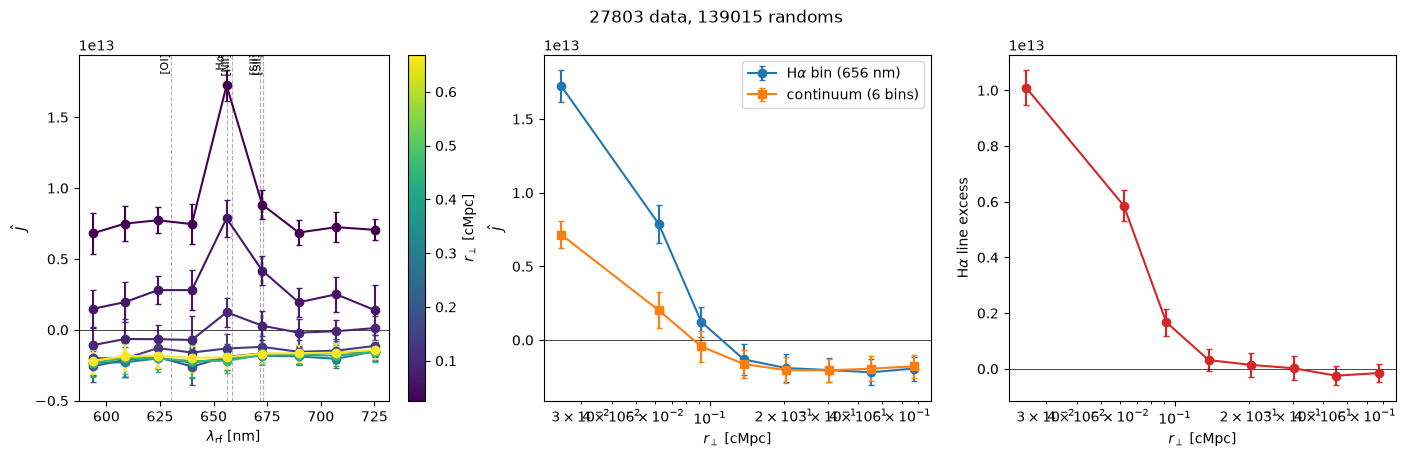

H-alpha line excess (bin 656 nm minus continuum bins [594 609 640 690 707 725] nm):
  r = 0.000 - 0.050 cMpc:  1.009e+13 ± 6.271e+11  (S/N  16.1)
  r = 0.050 - 0.074 cMpc:  5.855e+12 ± 5.535e+11  (S/N  10.6)
  r = 0.074 - 0.110 cMpc:  1.674e+12 ± 4.794e+11  (S/N  3.5)
  r = 0.110 - 0.164 cMpc:  3.127e+11 ± 4.083e+11  (S/N  0.8)
  r = 0.164 - 0.244 cMpc:  1.409e+11 ± 4.215e+11  (S/N  0.3)
  r = 0.244 - 0.362 cMpc:  2.005e+10 ± 4.388e+11  (S/N  0.0)
  r = 0.362 - 0.538 cMpc: -2.455e+11 ± 3.462e+11  (S/N -0.7)
  r = 0.538 - 0.800 cMpc: -1.532e+11 ± 3.211e+11  (S/N -0.5)


In [18]:
S3 = S_all.reshape(-1, n_r, n_wl)
C3 = C_all.reshape(-1, n_r, n_wl)
region = jackknife_regions(objs['ra'], objs['dec'], is_rand, N_JACKKNIFE)
full, jk = measure(S3, C3, objs['w'], is_rand, region, N_JACKKNIFE)
J_diff, J_note, pc_ratio = full
J_diff_err, J_note_err, pc_ratio_err = jk_err(jk)

n_per_region = np.bincount(region[~is_rand], minlength=N_JACKKNIFE)
print(f"jackknife: {N_JACKKNIFE} regions, {n_per_region.min()} - {n_per_region.max()} galaxies each")

plot_J(full, jk, r_bins, wl_bins, title=f'{(~is_rand).sum()} data, {is_rand.sum()} randoms')

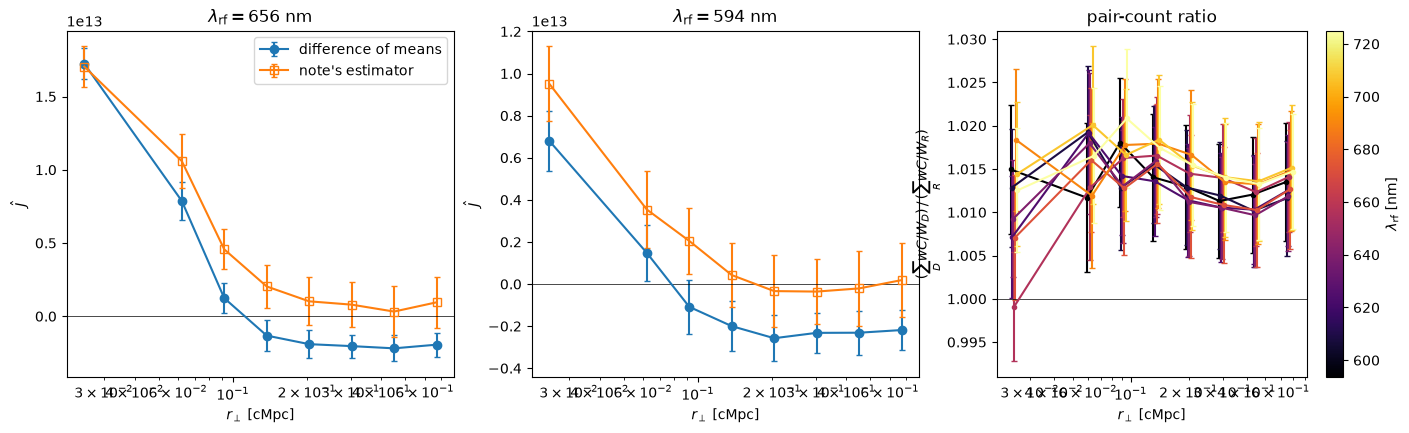

In [19]:
# the two estimators, and the pair-count ratio that separates them
j_line, cont = line_and_continuum(wl_bins)
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, j in zip(axs[:2], [j_line, cont[0]]):
    ax.errorbar(r_c, J_diff[:, j], J_diff_err[:, j], marker='o', capsize=2, label='difference of means')
    ax.errorbar(r_c, J_note[:, j], J_note_err[:, j], marker='s', mfc='none', capsize=2, label="note's estimator")
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xscale('log')
    ax.set_xlabel(r'$r_\perp$ [cMpc]')
    ax.set_ylabel(r'$\hat J$')
    ax.set_title(rf'$\lambda_{{\rm rf}} = {wl_c[j] * 1e3:.0f}$ nm')
axs[0].legend()

ax = axs[2]
cmap, norm = plt.get_cmap('inferno'), mpl.colors.Normalize(wl_c.min() * 1e3, wl_c.max() * 1e3)
for j in range(n_wl):
    ax.errorbar(r_c * (1 + 0.01 * (j - n_wl / 2)), pc_ratio[:, j], pc_ratio_err[:, j], marker='o', ms=3,
                capsize=2, color=cmap(norm(wl_c[j] * 1e3)))
ax.axhline(1, color='k', lw=0.5)
ax.set_xscale('log')
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel(r'$(\sum_D wC / W_D) \, / \, (\sum_R wC / W_R)$')
ax.set_title('pair-count ratio')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$\lambda_{\rm rf}$ [nm]')
plt.show()

### coverage diagnostics

Is the data-vs-random difference in measurements per object (the pair-count ratio ≠ 1) real, and where does it come from?

- weighted vs **unweighted**: if only the weighted ratio is off, it's the DESI weights correlating with SPHEREx coverage;
- **unique sky pixels in the disc** (before masking) vs **measurements**: separates sky coverage from the number of exposures
  and wavelengths per pixel;
- **Gaia-masked fraction**: data and randoms should be masked equally.

Errors are jackknife over the same regions.

data / randoms                             weighted         unweighted
measurements / object              1.0130 ± 0.0063     1.0011 ± 0.0178
sky pixels in disc / object        1.0126 ± 0.0062     0.9978 ± 0.0178
measurements / unmasked pixel      1.0000 ± 0.0002     1.0001 ± 0.0002
Gaia-masked fraction               0.9988 ± 0.0115     0.9552 ± 0.0264


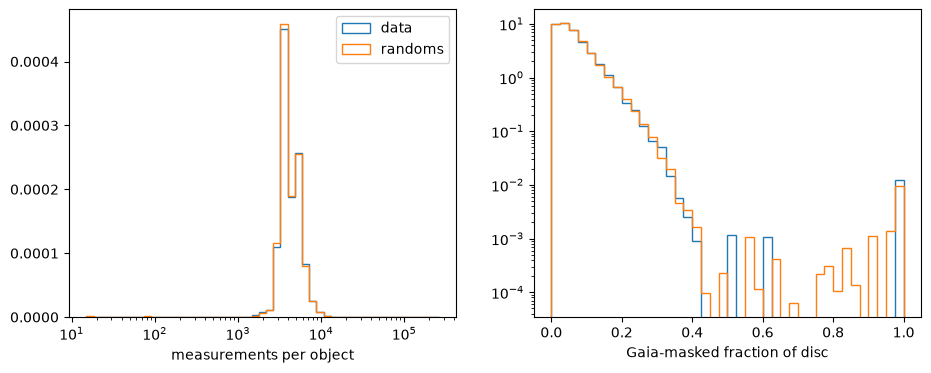

In [20]:
def ratio_jk(x, w):
    # (sum_D w x / W_D) / (sum_R w x / W_R), with jackknife error over `region`
    def ratio(keep):
        d, r = keep & ~is_rand, keep & is_rand
        return (np.sum(w[d] * x[d]) / w[d].sum()) / (np.sum(w[r] * x[r]) / w[r].sum())
    full = ratio(np.ones(n_obj, bool))
    jk = np.array([ratio(region != g) for g in range(N_JACKKNIFE)])
    return full, jk_err(jk)

n_meas = C_all.sum(1).astype(float)
masked_frac = np.where(npix_disc > 0, npix_masked / np.maximum(npix_disc, 1), np.nan)
ok = np.isfinite(masked_frac)
unit = np.ones(n_obj)

rows = [
    ('measurements / object',      n_meas),
    ('sky pixels in disc / object', npix_disc.astype(float)),
    ('measurements / unmasked pixel', np.where(npix_disc > npix_masked, n_meas / np.maximum(npix_disc - npix_masked, 1), 0.0)),
    ('Gaia-masked fraction',        np.where(ok, masked_frac, 0.0)),
]
print(f"{'data / randoms':32s} {'weighted':>18s} {'unweighted':>18s}")
for name, x in rows:
    (rw, ew), (ru, eu) = ratio_jk(x, objs['w']), ratio_jk(x, unit)
    print(f"{name:32s} {rw:8.4f} ± {ew:.4f}   {ru:8.4f} ± {eu:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
bins = np.geomspace(max(n_meas[n_meas > 0].min(), 1), n_meas.max(), 50)
for sel, label in [(~is_rand, 'data'), (is_rand, 'randoms')]:
    axs[0].hist(n_meas[sel], bins=bins, weights=objs['w'][sel], density=True, histtype='step', label=label)
    axs[1].hist(masked_frac[sel & ok], bins=np.linspace(0, 1, 41), weights=objs['w'][sel & ok], density=True,
                histtype='step', label=label)
axs[0].set_xscale('log')
axs[0].set_xlabel('measurements per object')
axs[1].set_xlabel('Gaia-masked fraction of disc')
axs[1].set_yscale('log')
axs[0].legend()
plt.show()

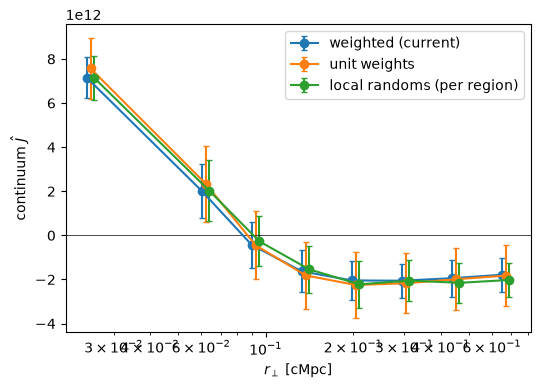

       r [cMpc]             weighted         unit weights        local randoms
0.000 - 0.050  7.15e+12 ± 9.3e+11  7.57e+12 ± 1.4e+12  7.13e+12 ± 9.8e+11
0.050 - 0.074  2.01e+12 ± 1.2e+12  2.35e+12 ± 1.7e+12  2.02e+12 ± 1.4e+12
0.074 - 0.110 -4.38e+11 ± 1.0e+12 -4.49e+11 ± 1.5e+12 -2.72e+11 ± 1.1e+12
0.110 - 0.164 -1.63e+12 ± 9.4e+11 -1.82e+12 ± 1.5e+12 -1.55e+12 ± 1.1e+12
0.164 - 0.244 -2.04e+12 ± 8.8e+11 -2.25e+12 ± 1.5e+12 -2.22e+12 ± 1.1e+12
0.244 - 0.362 -2.06e+12 ± 7.8e+11 -2.17e+12 ± 1.4e+12 -2.05e+12 ± 9.2e+11
0.362 - 0.538 -1.94e+12 ± 8.5e+11 -1.99e+12 ± 1.4e+12 -2.15e+12 ± 9.0e+11
0.538 - 0.800 -1.79e+12 ± 7.7e+11 -1.83e+12 ± 1.4e+12 -2.02e+12 ± 7.9e+11

randoms: d<I>/d ln(n_meas) = -3.69e+13; x 0.013 -> predicted offset -4.79e+11


In [22]:
def cont_mean(J):                      # (..., n_r, n_wl) -> (..., n_r), mean over the continuum bins
    return J[..., cont].mean(-1)

# weighted (what the notebook uses now)
J_w, err_w = cont_mean(full[0]), jk_err(cont_mean(jk[:, 0]))

# 1. unit weights
full_u, jk_u = measure(S3, C3, np.ones(n_obj), is_rand, region, N_JACKKNIFE)
J_u, err_u = cont_mean(full_u[0]), jk_err(cont_mean(jk_u[:, 0]))

# 2. local randoms: difference of means within each region, then a data-weighted average over regions
Sd, Cd, Wd = region_sums(S3, C3, objs['w'], region, ~is_rand, N_JACKKNIFE)
Sr, Cr, Wr = region_sums(S3, C3, objs['w'], region,  is_rand, N_JACKKNIFE)
with np.errstate(divide='ignore', invalid='ignore'):
    J_reg = cont_mean(Sd / Cd - Sr / Cr)                          # (n_regions, n_r)
good = np.isfinite(J_reg).all(1)
def loc_avg(keep):
    k = keep & good
    return (Wd[k, None] * J_reg[k]).sum(0) / Wd[k].sum()
J_l = loc_avg(np.ones(N_JACKKNIFE, bool))
err_l = jk_err(np.array([loc_avg(np.arange(N_JACKKNIFE) != g) for g in range(N_JACKKNIFE)]))

fig, ax = plt.subplots(figsize=(6, 4))
for k, (J, e, lab) in enumerate([(J_w, err_w, 'weighted (current)'), (J_u, err_u, 'unit weights'),
                                 (J_l, err_l, 'local randoms (per region)')]):
    ax.errorbar(r_c * (1 + 0.03 * (k - 1)), J, e, marker='o', capsize=2, label=lab)
ax.axhline(0, color='k', lw=0.5)
ax.set_xscale('log')
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel(r'continuum $\hat J$')
ax.legend()
plt.show()

print(f"{'r [cMpc]':>15s} {'weighted':>20s} {'unit weights':>20s} {'local randoms':>20s}")
for i in range(n_r):
    print(f"{r_bins[i]:.3f} - {r_bins[i + 1]:.3f} "
          + " ".join(f"{J[i]: .2e} ± {e[i]:.1e}" for J, e in [(J_w, err_w), (J_u, err_u), (J_l, err_l)]))

# 3. does the randoms' mean sky change with coverage?
r = is_rand & (n_meas > 0)
slope, _ = np.polyfit(np.log(n_meas[r]), S_all[r].sum(1) / n_meas[r], 1)
print(f"\nrandoms: d<I>/d ln(n_meas) = {slope:.2e}; x 0.013 -> predicted offset {slope * 0.013:.2e}")

nside   pixel data kept    mean continuum J, r > 0.16 cMpc
    8   7.33°    100.0%   -1.97e+12 ± 8.6e+11  (S/N -2.3)
   16   3.66°     99.9%   -1.88e+12 ± 8.6e+11  (S/N -2.2)
   32   1.83°     99.4%   -2.07e+12 ± 1.0e+12  (S/N -2.0)
   64   0.92°     95.8%   -1.47e+12 ± 5.9e+11  (S/N -2.5)
  128   0.46°     82.6%   -5.84e+11 ± 3.7e+11  (S/N -1.6)


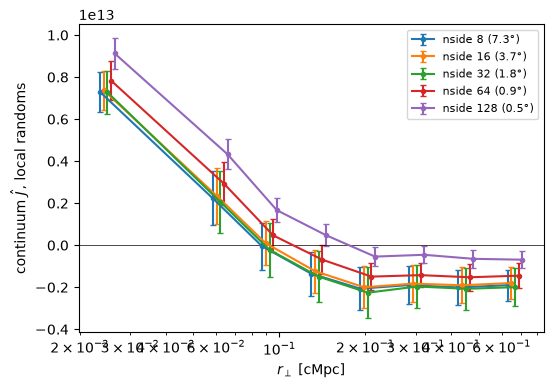

In [23]:
outer = r_c > 0.16   # r bins where the offset is flat

def group_sums(sel, g, n):
    # weighted sums of S, C, w over the objects in `sel`, grouped by g: (n, n_r, n_wl), (n, n_r, n_wl), (n,)
    w = objs['w'] * sel
    S = np.stack([np.bincount(g, weights=w * S_all[:, b], minlength=n) for b in range(n_bins)], 1)
    C = np.stack([np.bincount(g, weights=w * C_all[:, b], minlength=n) for b in range(n_bins)], 1)
    return S.reshape(n, n_r, n_wl), C.reshape(n, n_r, n_wl), np.bincount(g, weights=w, minlength=n)

def local_randoms(nside):
    pix = hp.ang2pix(nside, objs['ra'], objs['dec'], lonlat=True)
    _, first, g = np.unique(pix, return_index=True, return_inverse=True)
    n = g.max() + 1
    Sd, Cd, Wd = group_sums(~is_rand, g, n)
    Sr, Cr, _  = group_sums(is_rand, g, n)
    with np.errstate(divide='ignore', invalid='ignore'):
        Jg = cont_mean(Sd / Cd - Sr / Cr)                    # (n_pix, n_r)
    ok = np.isfinite(Jg).all(1)                              # pixel has data and randoms in every r bin
    reg = region[first]                                      # jackknife region of each pixel
    def avg(keep):
        k = keep & ok
        return (Wd[k, None] * Jg[k]).sum(0) / Wd[k].sum()
    J = avg(np.ones(n, bool))
    jk = np.array([avg(reg != r) for r in range(N_JACKKNIFE)])
    return J, jk, Wd[ok].sum() / Wd.sum()

fig, ax = plt.subplots(figsize=(6, 4))
print(f"{'nside':>5s} {'pixel':>7s} {'data kept':>9s}   {'mean continuum J, r > 0.16 cMpc':>32s}")
for k, nside in enumerate([8, 16, 32, 64, 128]):
    J, jk, frac = local_randoms(nside)
    m, m_err = J[outer].mean(), jk_err(jk[:, outer].mean(1))
    print(f"{nside:5d} {hp.nside2resol(nside, arcmin=True) / 60:6.2f}° {frac:9.1%}   {m: .2e} ± {m_err:.1e}  (S/N {m / m_err: .1f})")
    ax.errorbar(r_c * (1 + 0.03 * (k - 2)), J, jk_err(jk), marker='o', ms=3, capsize=2,
                label=f'nside {nside} ({hp.nside2resol(nside, arcmin=True) / 60:.1f}°)')
ax.axhline(0, color='k', lw=0.5)
ax.set_xscale('log')
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel(r'continuum $\hat J$, local randoms')
ax.legend(fontsize=8)
plt.show()